# Лабораторная работа № 1
## Иерархическая кластеризация


## Импорт библиотек


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
from IPython.display import display


## Подготовка данных


In [2]:
DATA_URL = "https://raw.githubusercontent.com/IvanManomenov/python_data_analytics/main/lab1/Econom_Cities_data.csv"
raw = pd.read_csv(DATA_URL, sep=';', decimal=',', na_values=[-9999])# -9999 - заглушка, меняю на na
features = ['Work', 'Price', 'Salary']

display(raw.head())

# Показываем строки с пропусками до их удаления.
display(raw.loc[raw[features].isna().any(axis=1)])

excluded = raw.loc[raw[features].isna().any(axis=1), 'City'].tolist()# дроп неполных записей
df = raw.dropna(subset=features).copy().reset_index(drop=True)

X = StandardScaler().fit_transform(df[features])# стандартизация
print(f'Исходно: {len(raw)} городов; в анализе: {len(df)}; исключены: {excluded}')

display(df[features].describe().round(2))


,City,Work,Price,Salary
0,Amsterdam,1714.0,65.6,49.0
1,Athens,1792.0,53.8,30.4
2,Bogota,2152.0,37.9,11.5
3,Bombay,2052.0,30.3,5.3
4,Brussels,1708.0,73.8,50.5


,City,Work,Price,Salary
6,Cairo,NaN,37.1,NaN
17,Jakarta,NaN,43.6,NaN


Исходно: 48 городов; в анализе: 46; исключены: ['Cairo', 'Jakarta']


,Work,Price,Salary
count,46.00,46.00,46.00
mean,1879.91,70.10,39.55
std,174.34,21.39,24.76
min,1583.00,30.30,2.70
25%,1745.25,51.78,14.38
50%,1849.00,70.95,43.65
75%,1976.25,81.90,59.70
max,2375.00,115.50,100.00


### Выбор числа кластеров


method,average,complete,single,ward
k,,,,
2,0.4705,0.4705,0.2869,0.4705
3,0.4197,0.3875,0.0250,0.3612
4,0.3718,0.3658,0.0796,0.3551
5,0.3813,0.3795,0.0099,0.3475
6,0.3831,0.3905,0.0626,0.3657
7,0.3503,0.3953,0.0522,0.3959
8,0.3544,0.3932,0.3073,0.3990


,k,silhouette,min_size,sizes
0,2,0.4705,21,"25, 21"
1,3,0.3612,7,"25, 7, 14"
2,4,0.3551,6,"19, 7, 14, 6"
3,5,0.3475,5,"14, 7, 14, 5, 6"
4,6,0.3657,2,"14, 7, 12, 5, 6, 2"
5,7,0.3959,2,"14, 7, 12, 5, 2, 4, 2"
6,8,0.3990,2,"14, 7, 5, 7, 5, 2, 4, 2"


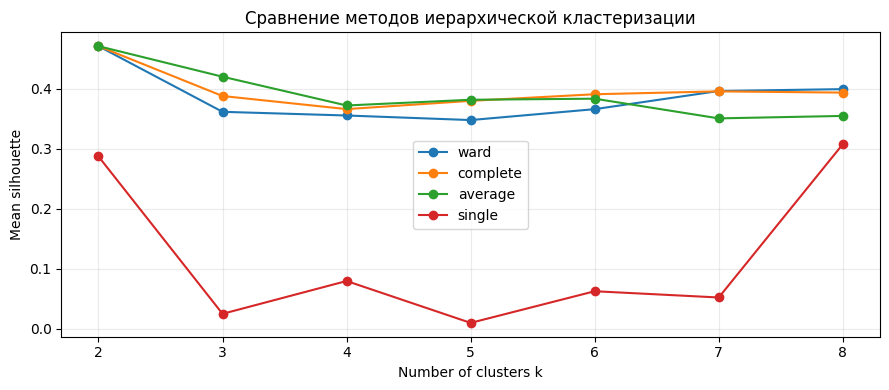

Выбрано k = 2; silhouette = 0.4705
Высота предпоследнего и последнего объединений: [ 5.0611 12.4003]


In [3]:
# Сравниваем правила объединения при одинаковой евклидовой метрике.
methods = ['ward', 'complete', 'average', 'single']
ks = range(2, 9)
links = {m: linkage(X, method=m, metric='euclidean') for m in methods}
rows = []
for method in methods:
  # Проверяем число кластеров от 2 до 8
    for k in ks:
        labels = cut_tree(links[method], n_clusters=k).ravel()
        sizes = np.bincount(labels)
        rows.append({'method': method, 'k': k,
                     'silhouette': silhouette_score(X, labels),
                     'min_size': sizes.min(), 'sizes': ', '.join(map(str, sizes))})
scores = pd.DataFrame(rows)
display(scores.pivot(index='k', columns='method', values='silhouette').round(4))
display(scores.loc[scores.method.eq('ward'), ['k', 'silhouette', 'min_size', 'sizes']].round(4))
fig, ax = plt.subplots(figsize=(9, 4))
for method in methods:
    part = scores[scores.method.eq(method)]
    ax.plot(part.k, part.silhouette, marker='o', label=method)
ax.set(xlabel='Number of clusters k', ylabel='Mean silhouette',
       title='Сравнение методов иерархической кластеризации', xticks=list(ks))
ax.legend()
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

best_k = int(scores.loc[scores.method.eq('ward')].sort_values(['silhouette', 'k'], ascending=[False, True]).iloc[0]['k'])
Z = links['ward']
labels = cut_tree(Z, n_clusters=best_k).ravel() + 1
df['Cluster'] = labels
print(f'Выбрано k = {best_k}; silhouette = {silhouette_score(X, labels):.4f}')
print('Высота предпоследнего и последнего объединений:', np.round(Z[-2:, 2], 4))


### Обоснование решения

Выбраны **Ward и 2 кластера**. Силуэт — **0,4705** против **0,3612** при трёх группах. Complete и average при двух группах дают то же разбиение. Получаются группы 25 и 21 город

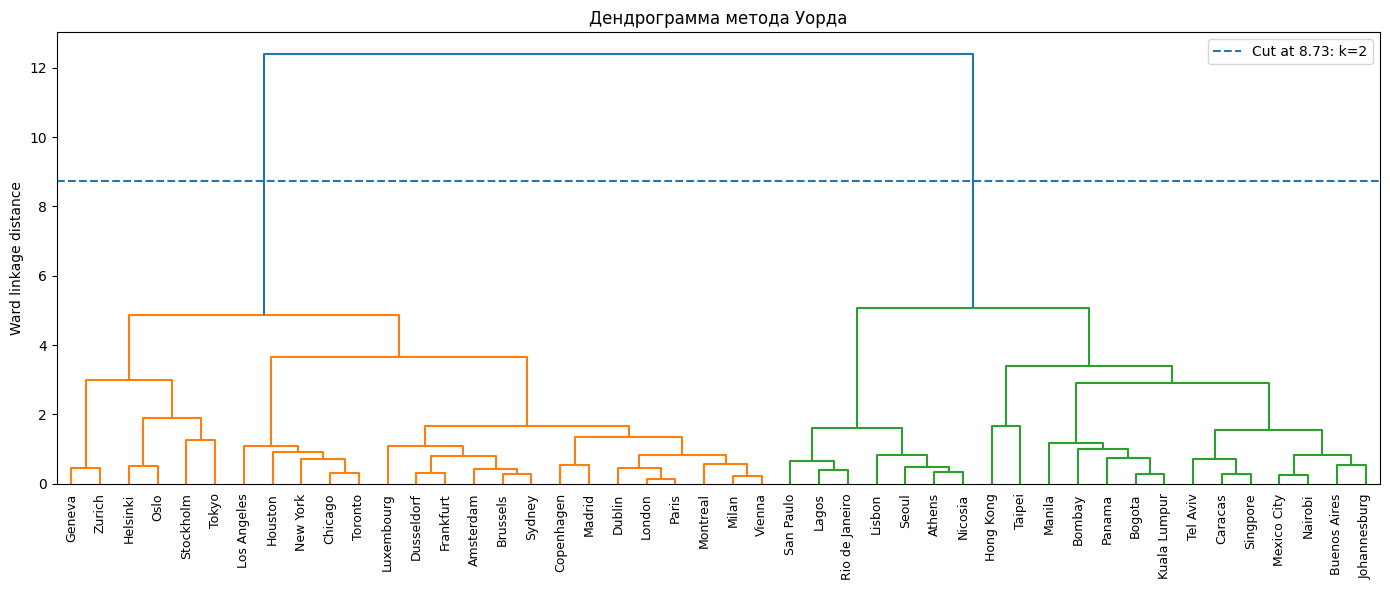

In [4]:
# Разрез между двумя последними слияниями оставляет две ветви дерева.
# Высота Ward отражает стоимость объединения, а не расстояние между отдельными городами.
cut_height = (Z[-2, 2] + Z[-1, 2]) / 2
fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(Z, labels=df.City.str.replace('_', ' ').tolist(),
           leaf_rotation=90, leaf_font_size=9, color_threshold=cut_height, ax=ax)
ax.axhline(cut_height, linestyle='--', label=f'Cut at {cut_height:.2f}: k={best_k}')
ax.set(title='Дендрограмма метода Уорда', ylabel='Ward linkage distance')
ax.legend(); plt.tight_layout(); plt.show()


### Состав и профили кластеров


,Cities,Work_mean,Price_mean,Salary_mean
Cluster,,,,
1,25,1789.24,84.97,59.03
2,21,1987.86,52.40,16.35


,Work,Price,Salary
Cluster: medians,,,
1,1768.0,79.8,58.2
2,1971.0,49.8,12.5


Кластер 1: 25 городов
Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los Angeles, Luxembourg, Madrid, Milan, Montreal, New York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, Vienna, Zurich
Кластер 2: 21 городов
Athens, Bogota, Bombay, Buenos Aires, Caracas, Hong Kong, Johannesburg, Kuala Lumpur, Lagos, Lisbon, Manila, Mexico City, Nairobi, Nicosia, Panama, Rio de Janeiro, San Paulo, Seoul, Singpore, Taipei, Tel Aviv


,City,Work,Price,Salary,Cluster
0,Amsterdam,1714.0,65.6,49.0,1
1,Brussels,1708.0,73.8,50.5,1
2,Chicago,1924.0,73.9,61.9,1
3,Copenhagen,1717.0,91.3,62.9,1
4,Dublin,1759.0,76.0,41.4,1
5,Dusseldorf,1693.0,78.5,60.2,1
6,Frankfurt,1650.0,74.5,60.4,1
7,Geneva,1880.0,95.9,90.3,1
8,Helsinki,1667.0,113.6,66.6,1
9,Houston,1978.0,71.9,46.3,1


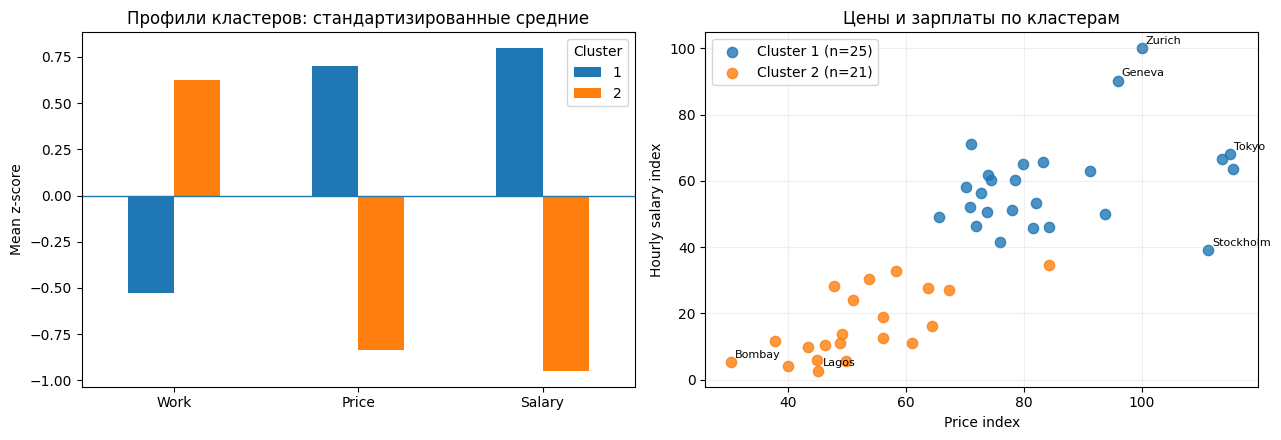

In [5]:
# Для интерпретации возвращаемся к исходным единицам и показываем состав всех групп.
profile = df.groupby('Cluster')[features].mean()
summary = df.groupby('Cluster').agg(
    Cities=('City', 'size'), Work_mean=('Work', 'mean'),
    Price_mean=('Price', 'mean'), Salary_mean=('Salary', 'mean'))
display(summary.round(2))
display(df.groupby('Cluster')[features].median().round(2).rename_axis('Cluster: medians'))
for cluster, group in df.groupby('Cluster'):
    print(f'Кластер {cluster}: {len(group)} городов')
    print(', '.join(group.City.str.replace('_', ' ').sort_values()))
display(df.sort_values(['Cluster', 'City']).reset_index(drop=True))

# Стандартизированные средние позволяют сопоставить признаки на одном графике.
# Диаграмма Price–Salary — только проекция: кластеризация использует все три признака.
standard_profiles = pd.DataFrame(X, columns=features).assign(Cluster=labels).groupby('Cluster').mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
standard_profiles.T.plot.bar(ax=axes[0], rot=0)
axes[0].axhline(0, linewidth=1)
axes[0].set(title='Профили кластеров: стандартизированные средние', ylabel='Mean z-score')
for cluster, group in df.groupby('Cluster'):
    axes[1].scatter(group.Price, group.Salary, s=55, alpha=.8,
                    label=f'Cluster {cluster} (n={len(group)})')
    for _, row in group.iterrows():
        if row.City in ['Zurich', 'Geneva', 'Tokyo', 'Lagos', 'Bombay', 'Stockholm']:
            axes[1].annotate(row.City, (row.Price, row.Salary), xytext=(3, 3),
                             textcoords='offset points', fontsize=8)
axes[1].set(title='Цены и зарплаты по кластерам', xlabel='Price index', ylabel='Hourly salary index')
axes[1].legend(); axes[1].grid(alpha=.2)
plt.tight_layout(); plt.show()
# Проекция показывает два признака; модель использует все три.


### Экономическая интерпретация

| Кластер | Число городов | Среднее Work | Среднее Price | Среднее Salary | Интерпретация |
|---|---:|---:|---:|---:|---|
| 1 | 25 | 1789,24 | 84,97 | 59,03 | Более высокие цены и почасовые зарплаты, меньшее рабочее время |
| 2 | 21 | 1987,86 | 52,40 | 16,35 | Более низкие цены и почасовые зарплаты, большее рабочее время |

**Кластер 1.** Например, Amsterdam, London, New York, Tokyo и Zurich. Относительно второй группы здесь выше средние индексы цен и заработной платы и ниже среднее рабочее время. Это широкая группа с внутренними различиями: все её города нельзя считать одинаково дорогими или одинаково высокооплачиваемыми.

**Кластер 2.** Например, Athens, Bombay, Hong Kong, Mexico City и Seoul. Средний показатель рабочего времени выше примерно на **198,62 часа**, а средние индексы цен и зарплаты ниже. Отличие по зарплате выражено сильнее, чем отличие по ценам.


### Что будет, если взять другое количество кластеров?

Давайте посмотрим, как изменятся профили и состав групп, если разделить города на 3 и 4 кластера методом Уорда.


3 кластера: силуэт = 0.3612


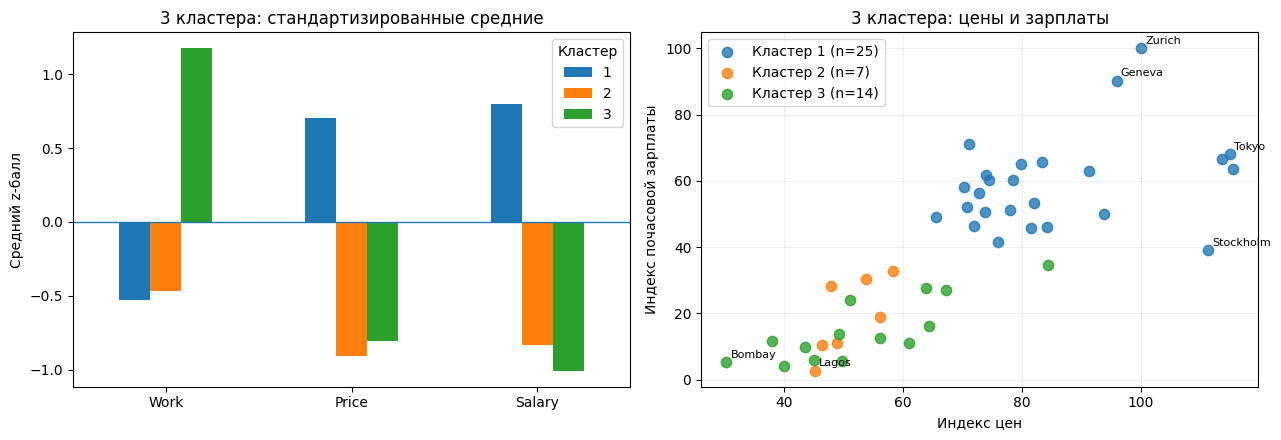

4 кластера: силуэт = 0.3551


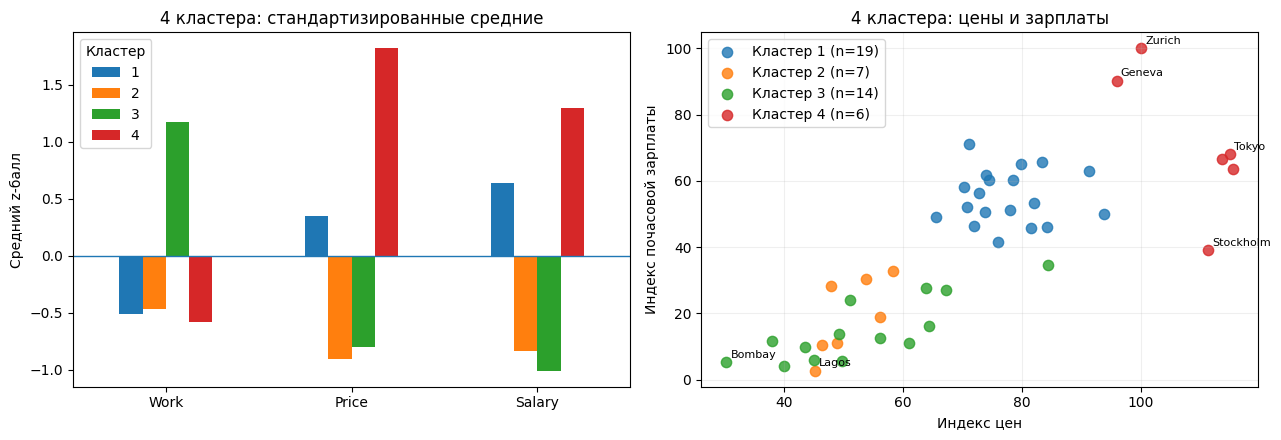

In [6]:
# Разрезаем то же дерево Ward на 3 и 4 группы, сохраняя исходное решение с двумя кластерами.
for k in [3, 4]:
    alternative_labels = cut_tree(Z, n_clusters=k).ravel() + 1
    alternative_df = df.assign(Cluster=alternative_labels)
    alternative_profiles = (pd.DataFrame(X, columns=features)
                            .assign(Cluster=alternative_labels)
                            .groupby('Cluster').mean())
    print(f'{k} кластера: силуэт = {silhouette_score(X, alternative_labels):.4f}')

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    alternative_profiles.T.plot.bar(ax=axes[0], rot=0)
    axes[0].axhline(0, linewidth=1)
    axes[0].set(title=f'{k} кластера: стандартизированные средние',
                ylabel='Средний z-балл')
    axes[0].legend(title='Кластер')

    # На диаграмме показаны цены и зарплаты; дерево построено по всем трём признакам.
    for cluster, cities in alternative_df.groupby('Cluster'):
        axes[1].scatter(cities.Price, cities.Salary, s=55, alpha=.8,
                        label=f'Кластер {cluster} (n={len(cities)})')
        for _, city in cities.iterrows():
            if city.City in ['Zurich', 'Geneva', 'Tokyo', 'Lagos', 'Bombay', 'Stockholm']:
                axes[1].annotate(city.City, (city.Price, city.Salary), xytext=(3, 3),
                                 textcoords='offset points', fontsize=8)
    axes[1].set(title=f'{k} кластера: цены и зарплаты',
                xlabel='Индекс цен', ylabel='Индекс почасовой зарплаты')
    axes[1].legend()
    axes[1].grid(alpha=.2)
    plt.tight_layout()
    plt.show()


### Проверка чувствительности


In [7]:
# ARI сравнивает состав групп независимо от их номеров: 1 означает полное совпадение.
agreement = []
for method in methods:
    other = cut_tree(links[method], n_clusters=best_k).ravel()
    agreement.append({'method': method, 'ARI_vs_Ward': adjusted_rand_score(labels, other)})
display(pd.DataFrame(agreement).round(4))

# Чувствительность к медианному заполнению двух неполных городов.
filled = raw.copy()
filled[features] = filled[features].fillna(filled[features].median())
X_filled = StandardScaler().fit_transform(filled[features])
filled['Cluster_imputed'] = cut_tree(linkage(X_filled, method='ward'), n_clusters=best_k).ravel()
common = df[['City', 'Cluster']].merge(filled[['City', 'Cluster_imputed']], on='City', validate='one_to_one')
imputation_ari = adjusted_rand_score(common.Cluster, common.Cluster_imputed)
print(f'ARI на 46 полных городах после медианного заполнения: {imputation_ari:.4f}')

# Поочерёдно исключаем каждый город и заново оцениваем масштабирование и иерархию.
# Это проверяет чувствительность к отдельным наблюдениям, а не универсальность кластеров.
loo = []
for i in range(len(df)):
    mask = np.arange(len(df)) != i
    Xi = StandardScaler().fit_transform(df.loc[mask, features])
    li = cut_tree(linkage(Xi, method='ward'), n_clusters=best_k).ravel()
    loo.append({'Excluded_city': df.loc[i, 'City'],
                'ARI': adjusted_rand_score(labels[mask], li)})
loo = pd.DataFrame(loo)
print(f'Исключение одного города: min ARI = {loo.ARI.min():.4f}; median ARI = {loo.ARI.median():.4f}')
display(loo.sort_values('ARI').head().round(4))

# Сохраняем назначения кластеров, профили и результаты подбора параметров.
assignment = df.sort_values(['Cluster', 'City']).reset_index(drop=True)
assignment.to_csv('lab1_cities_clusters.csv', index=False, encoding='utf-8-sig')
summary.to_csv('lab1_cluster_profiles.csv', encoding='utf-8-sig')
scores.to_csv('lab1_hierarchical_scores.csv', index=False, encoding='utf-8-sig')


,method,ARI_vs_Ward
0,ward,1.0000
1,complete,1.0000
2,average,1.0000
3,single,0.0083


ARI на 46 полных городах после медианного заполнения: 1.0000
Исключение одного города: min ARI = 0.6686; median ARI = 1.0000


,Excluded_city,ARI
29,New_York,0.6686
43,Toronto,0.8263
37,Singpore,0.8263
7,Chicago,0.9111
14,Hong_Kong,0.9111


### Вывод

**Два кластера Ward: 25 и 21 город, силуэт 0,4705.** Первая группа имеет более высокие цены и зарплаты при меньшем рабочем времени; вторая — более низкие цены и зарплаты при большем рабочем времени.

Complete и average дают тот же состав групп. Медианное заполнение пропусков не меняет назначения полных наблюдений (ARI = 1). При исключении одного города медианный ARI = 1, но минимум **0,6686 при исключении New York**: чувствительность к отдельным наблюдениям существенна.
